### ДЗ 2: классификация изображений

In [45]:
# импорт библиотек

import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Dataset, Subset, random_split

import numpy as np
import pandas as pd
import random
import matplotlib.pyplot as plt
import copy
from pathlib import Path
from PIL import Image

from scipy import ndimage

In [46]:
# фиксируем seed
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

# Определяем устройство: GPU, если доступен, иначе CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Используемое устройство: {device}")
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.set_num_threads(4)

Используемое устройство: cpu


In [47]:
# найти границы объекта
def find_bounds(image, threshold=15, min_pixels=3):
    pixels = np.asarray(image)
    background = int(np.median(np.concatenate([pixels[0], pixels[-1], pixels[:, 0], pixels[:, -1]])))
    mask = np.abs(pixels.astype(np.int16) - background) > threshold

    rows = np.where(mask.sum(axis=1) >= min_pixels)[0]
    cols = np.where(mask.sum(axis=0) >= min_pixels)[0]
    return (int(cols[0]), int(rows[0]), int(cols[-1] + 1), int(rows[-1] + 1)), background


# основная функция обрезки
def crop_foreground(image):
    image = image.convert("L")
    bounds, background = find_bounds(image)
    if bounds is None:
        return image

    x0, y0, x1, y1 = bounds
    margin = max(2, int(0.04 * max(x1 - x0, y1 - y0)))
    cropped = image.crop((
        max(0, x0 - margin),
        max(0, y0 - margin),
        min(image.width, x1 + margin),
        min(image.height, y1 + margin)
    ))

    # дополняем до квадрата
    side = max(cropped.size)
    square = Image.new("L", (side, side), color=background)
    square.paste(cropped, ((side - cropped.width) // 2, (side - cropped.height) // 2))
    return square

In [48]:
# путь к папке с данными
data_dir = Path("mri_classification_dataset")

# преобразование данных
image_size = 128
base_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Lambda(crop_foreground),
    transforms.Resize((image_size, image_size)),
    transforms.ToTensor(),
])

In [49]:
train_dataset = datasets.ImageFolder(data_dir/"train", transform=base_transform)
print('Соответствие классов:', train_dataset.class_to_idx)

val_dataset = datasets.ImageFolder(data_dir/"val", transform=base_transform)
print('Соответствие классов:', val_dataset.class_to_idx)

print(f"Размер train: {len(train_dataset)}")
print(f"Размер val: {len(val_dataset)}")

Соответствие классов: {'class_0': 0, 'class_1': 1, 'class_2': 2, 'class_3': 3, 'class_4': 4}
Соответствие классов: {'class_0': 0, 'class_1': 1, 'class_2': 2, 'class_3': 3, 'class_4': 4}
Размер train: 1390
Размер val: 298


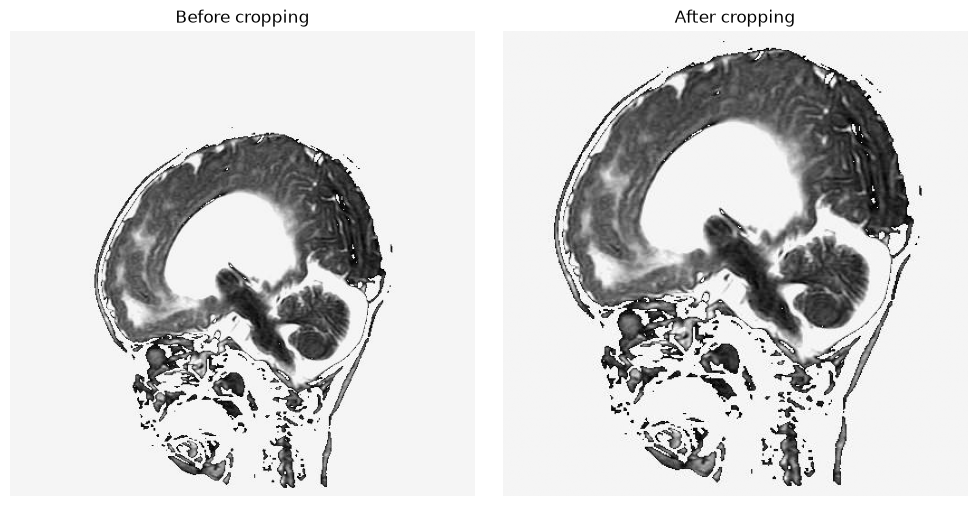

До обрезки: (512, 512)
После обрезки: (415, 415)


In [50]:
# проверка функции обрезки

image_path, label = train_dataset.samples[2]
image = Image.open(image_path)
cropped = crop_foreground(image)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(image, cmap='gray')
axes[0].set_title("Before cropping")
axes[0].axis('off')
axes[1].imshow(cropped, cmap='gray')
axes[1].set_title("After cropping")
axes[1].axis('off')

plt.tight_layout()
plt.show()

print("До обрезки:", image.size)
print("После обрезки:", cropped.size)

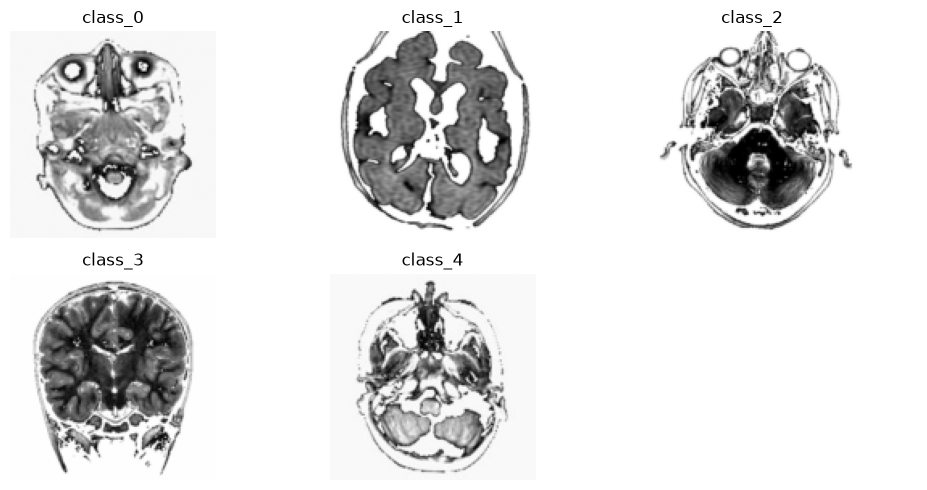

In [51]:
# посмотрим по одному изображению из каждого класса
fig, axes = plt.subplots(2, 3, figsize=(10, 5))
classes = train_dataset.classes  # список названий классов

for i, ax in enumerate(axes.flat):
    if i < len(classes):
        index = train_dataset.targets.index(i)
        img, label = train_dataset[index]
        ax.imshow(img.squeeze(0).numpy(), cmap="gray")
        ax.set_title(classes[label])
    ax.axis('off')
plt.tight_layout()
plt.show()

In [52]:
# создание DataLoader
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False, num_workers=0)

Данные подготовлены. Дальше - построение свёрточной нейронной сети.

In [53]:
# класс взят из обучающего ноутбука, но изменен под задачу

class CNN(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()
        self.conv_layers = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),

            nn.Conv2d(16, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),

            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),


            nn.AdaptiveAvgPool2d((4, 4)),  # уменьшаем размер признаков до 4 x 4
        )
        self.fc_layers = nn.Sequential(
            nn.Linear(128 * 4 * 4, 128),
            nn.ReLU(), # ReLU слой, иначе получим два подряд линейных слоя, в чем нет смысла - их работа моделируется одним линейным слоем
            nn.Dropout(0.1),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.conv_layers(x)
        x = x.view(x.size(0), -1)  # вытягиваем изображение в вектор размера 128 x 4 x 4, чтобы подать на вход полносвязному слою
        x = self.fc_layers(x)
        return x

model = CNN(num_classes=5).to(device)
print(model)

CNN(
  (conv_layers): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (9): ReLU()
    (10): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (12): ReLU()
    (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (14): Conv2d(32, 64, kernel

In [54]:
# оптимизатор и функция потерь

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

# обучение нестабильно => будем менять learning rate
scheduler = optim.lr_scheduler.MultiStepLR(optimizer, milestones=[5, 12], gamma=0.3)

In [55]:
# обучение нейросети (взят из обучающего ноутбука)

epochs = 15
train_loss_history = []
val_acc_history = []
best_acc = -1.0
best_state = None
best_epoch = 0

for epoch in range(epochs):
    # Переключаем модель в режим обучения (важно для Dropout, BatchNorm и т.п.)
    model.train()
    running_loss = 0.0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        # Обнуляем градиенты, чтобы они не накапливались от прошлых итераций
        optimizer.zero_grad()

        # Шаг 1. Прямой проход: получаем предсказания модели
        outputs = model(inputs)

        # Шаг 2. Вычисляем потери между предсказаниями и истинными метками
        loss = criterion(outputs, labels)

        # Шаг 3. Обратный проход: вычисляем градиенты по всем параметрам
        loss.backward()

        # Шаг 4. Обновляем веса с помощью оптимизатора
        optimizer.step()

        # Суммируем потери для отчёта за эпоху
        running_loss += loss.item() * inputs.size(0)

    epoch_loss = running_loss / len(train_dataset)
    train_loss_history.append(epoch_loss)

    # Переключаем модель в режим оценки качества
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():  # отключаем расчёт градиентов для ускорения вычислений
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (preds == labels).sum().item()

    val_acc = correct / total
    val_acc_history.append(val_acc)
    if val_acc > best_acc:
        best_acc = val_acc
        best_epoch = epoch + 1
        best_state = copy.deepcopy(model.state_dict())

    print(f"Epoch {epoch+1}/{epochs}, Loss: {epoch_loss:.4f}, Val Acc: {val_acc:.4f}")
    scheduler.step()

model.load_state_dict(best_state)

Epoch 1/15, Loss: 1.4762, Val Acc: 0.2114
Epoch 2/15, Loss: 0.7985, Val Acc: 0.4799
Epoch 3/15, Loss: 0.4795, Val Acc: 0.7416
Epoch 4/15, Loss: 0.3150, Val Acc: 0.8423
Epoch 5/15, Loss: 0.2045, Val Acc: 0.8859
Epoch 6/15, Loss: 0.1285, Val Acc: 0.9362
Epoch 7/15, Loss: 0.0817, Val Acc: 0.9631
Epoch 8/15, Loss: 0.0663, Val Acc: 0.9799
Epoch 9/15, Loss: 0.0475, Val Acc: 0.9799
Epoch 10/15, Loss: 0.0436, Val Acc: 0.9664
Epoch 11/15, Loss: 0.0349, Val Acc: 0.9698
Epoch 12/15, Loss: 0.0273, Val Acc: 0.9698
Epoch 13/15, Loss: 0.0194, Val Acc: 0.9832
Epoch 14/15, Loss: 0.0166, Val Acc: 0.9799
Epoch 15/15, Loss: 0.0159, Val Acc: 0.9832


<All keys matched successfully>

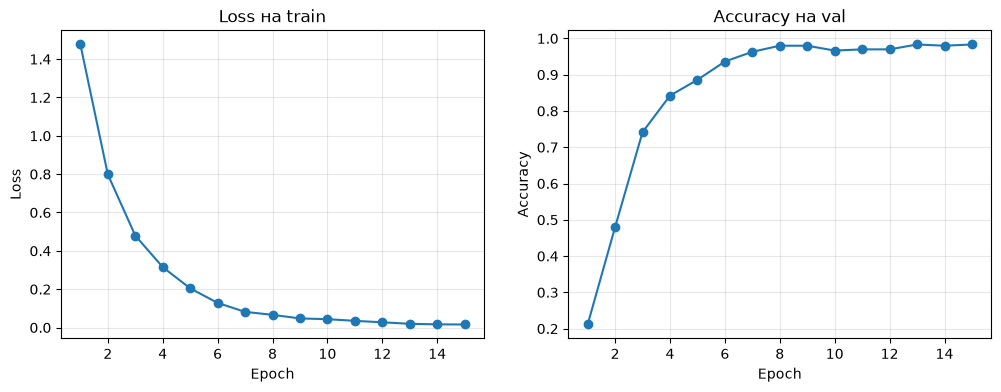

In [62]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(range(1, epochs+1), train_loss_history, marker='o')
plt.title('Loss на train')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(range(1, epochs+1), val_acc_history, marker='o')
plt.title('Accuracy на val')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.grid(True, alpha=0.3)

plt.show()

Некоторые ячейки с анализом ошибок были удалены, т.к. больше относились к отладочной информации. Они использовались для того, чтобы понять, на каких классах модель показывает наихудшее предсказание (такими были 1 и 4 классы).

Также эксперименты показывают, что аугментация для этих изображений не дает выигрыша при обучении, видимо искажение изображения критично для классификации.

In [63]:
# сохранение модели

selected_model = model
checkpoint = {
    'state_dict': selected_model.state_dict(),
    'num_classes': 5,
    'image_size': image_size,
    'transform': 'ToTensor',
    'classes': classes,
    'seed': seed,
    'best_epoch': best_epoch,
    'val_accuracy': best_acc,
}
torch.save(checkpoint, 'selected.pt')
checkpoint = torch.load('selected.pt', map_location=device, weights_only=True)
selected_model = CNN(num_classes=checkpoint['num_classes']).to(device)
selected_model.load_state_dict(checkpoint['state_dict'])

<All keys matched successfully>

In [64]:
# изображения для тестовой выборки лежат не по папкам =>
# ImageFolder не поможет

# класс взят из обучающего ноутбука и переписан, чтобы подходить под структуру датасета

class TestDataset(Dataset):
    def __init__(self, root, transform):
        self.files = sorted(Path(root).glob("*.jpg"))
        self.ids = [path.stem for path in self.files]
        self.transform = transform

    def __len__(self):
        return len(self.files)

    def __getitem__(self, index):
        image = Image.open(self.files[index]).convert("RGB")
        return self.transform(image), self.ids[index]

In [65]:
assert checkpoint['image_size'] == image_size and checkpoint['transform'] == 'ToTensor'
test_dataset = TestDataset(data_dir/"test", base_transform)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False, num_workers=0)

print(f"Test size: {len(test_dataset)}")

Test size: 300


Из цикла обучения берём только часть с оценкой, чтобы получить предсказания

In [66]:
# Переводим модель в режим оценки
selected_model.eval()

test_ids = []
test_preds = []

with torch.no_grad():
    for inputs, ids in test_loader:
        inputs = inputs.to(device)
        outputs = selected_model(inputs)
        _, preds = torch.max(outputs, 1)
        test_preds.extend(preds.cpu().numpy())
        # ID сохраняем из того же батча, что и предсказания
        test_ids.extend(ids)

In [67]:
# Создаём DataFrame и проверяем формат CSV
submission = pd.DataFrame({'id': test_ids, 'label': test_preds})
sample = pd.read_csv(data_dir / 'sample_submission.csv')
assert submission['id'].is_unique and set(submission['id']) == set(sample['id'])
assert len(submission) == len(test_dataset) == 300
assert submission['label'].between(0, 4).all()
assert pd.api.types.is_integer_dtype(submission['label'])
submission = submission.set_index('id').loc[sample['id']].reset_index()
submission.to_csv('submission.csv', index=False)
print("Файл submission.csv сохранён")
print(submission.head())

Файл submission.csv сохранён
          id  label
0  img_00001      1
1  img_00002      3
2  img_00003      0
3  img_00004      1
4  img_00005      0
